# ACSST5Y2024.S1701-Data.csv

Executed source EDA. Only aggregate outputs are retained. Public inputs remain local. No causal inference or attendance model is used.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'public/data/manifest.json').exists())
manifest = json.loads((ROOT/'public/data/manifest.json').read_text())
areas = pd.read_json(ROOT/'public/data/areas.json')
counties = {c + ' County' for c in manifest['geography']}
print('Mode:', manifest['mode'], '| Version:', manifest['datasetVersion'])


Mode: observed | Version: 5d7db3d37ab5


National/multiregion rows before filtering: 3086
Study-area rows: 490


S1701_C03_001E    2
S1701_C03_001M    2
Name: missing, dtype: int64

,S1701_C03_001E,S1701_C03_001M
count,488.000000,488.000000
mean,12.195697,6.522131
std,8.296953,3.403314
min,0.600000,0.700000
25%,6.200000,4.000000
50%,10.000000,6.050000
75%,17.025000,8.600000
max,58.300000,25.800000


S1701_C03_001E    8
S1701_C03_001M    3
Name: IQR outliers; inspect, do not delete automatically, dtype: int64

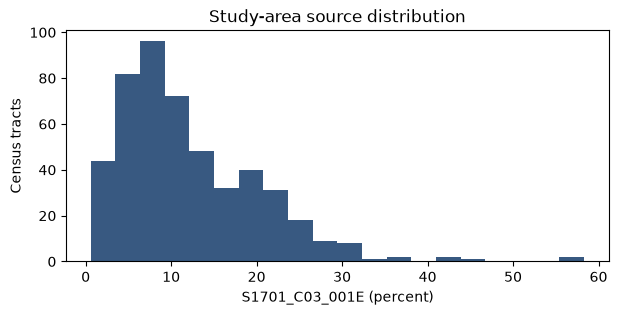

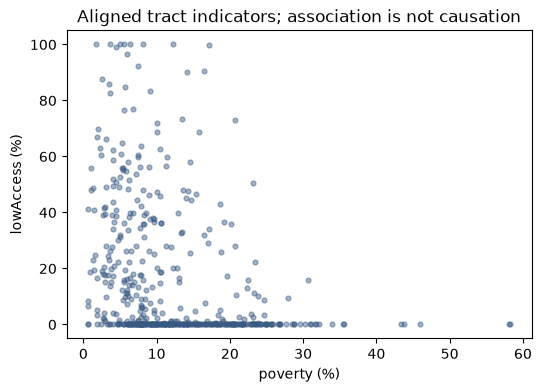

In [2]:
df = pd.read_csv(ROOT/'data/raw/ACSST5Y2024.S1701-Data.csv', dtype=str, encoding='utf-8-sig')
print('National/multiregion rows before filtering:', len(df))
df = df[df.GEO_ID.str.startswith('1400000US12', na=False)].copy()
columns = ['S1701_C03_001E', 'S1701_C03_001M']
values = df[columns].apply(pd.to_numeric, errors='coerce')
print('Study-area rows:', len(df))
display(values.isna().sum().rename('missing'))
display(values.describe())
q1, q3 = values.quantile(.25), values.quantile(.75)
display(((values < q1 - 1.5*(q3-q1)) | (values > q3 + 1.5*(q3-q1))).sum().rename('IQR outliers; inspect, do not delete automatically'))
fig, ax = plt.subplots(figsize=(7,3))
values[columns[0]].dropna().hist(ax=ax,bins=20,color='#385981',grid=False)
ax.set(xlabel='S1701_C03_001E (percent)',ylabel='Census tracts',title='Study-area source distribution')
plt.show()
fig, ax = plt.subplots(figsize=(6,4))
areas.plot.scatter(x='poverty',y='lowAccess',ax=ax,color='#385981',alpha=.45,s=12)
ax.set(xlabel='poverty (%)',ylabel='lowAccess (%)',title='Aligned tract indicators; association is not causation')
plt.show()


## Interpretation and limitations

The displayed row counts and missingness are observed from these local files. Numeric outliers are retained unless a documented source error exists. Statistical geography is the census tract; retailer locations are points, not service coverage. Estimates have mixed vintages and cannot establish individual need, travel time, attendance, or causal impact. ACS poverty/SNAP sentinel values remain missing. Tract-level associations do not describe individual households. The 2020 geometry joins by exact GEOID, never by tract label. See `docs/data_audit.md` and `docs/transformations.md` for exclusions and lineage.